# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

---

## Recap from H1: what you committed to

*Copied from my H1 plan. I will review and update this recap if my implementation changes.*

**Problem (from H1):**

In office buildings, electricity can be wasted when lights or air conditioning are left running in empty rooms. This gave me the idea for RoomSense, a small neural network that uses temperature, humidity, light and CO₂ readings to predict whether a room is occupied. The goal is to help facilities staff identify rooms worth checking for unnecessary energy use. RoomSense will only make predictions, not control electricity.

**Technique(s) (from H1):**

I will build a small feedforward neural network with Python and NumPy. It will take four sensor readings, use one hidden layer with six neurons and produce an occupancy score between 0 and 1. Gradient descent and backpropagation will adjust its weights during training. This connects to P8 weighted-sum classification, P9 gradient descent and D3 perceptrons.

**Data (from H1):**

I will use the UCI Occupancy Detection dataset, which contains 20,560 labelled office-room observations. It includes temperature, humidity, light, CO₂ and humidity ratio. The occupancy label is 0 (empty) or 1 (occupied). I will use the first four sensor readings as inputs and the provided training and test files for evaluation.

Dataset: https://archive.ics.uci.edu/dataset/357/occupancy-detection

**What makes this HD-level (from H1):**

My plan is to build and understand a small neural network from scratch, compare it with my P8 weighted-sum classifier, and investigate how learning rates and unreliable sensor readings affect its results. The comparison could also show that the simpler model is enough for this dataset.

**Pivot since H1 (if any):**

No change currently planned. I will record any necessary changes and the reasons here.


In [43]:
# --- SETUP ---

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Use a fixed seed to make results reproducible
SEED = 42
np.random.seed(SEED)

# Project folders
DATA_DIR = Path("data/raw")
FIGURES_DIR = Path("figures")

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check the environment
print("RoomSense Setup")
print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Current folder:", Path.cwd())
print("Setup OK!")

RoomSense Setup
Python version: 3.12.15
NumPy version: 2.5.4
Current folder: d:\Projects\RoomSense
Setup OK!


### Data

In [44]:
# --- DATA ---

import csv

# The four sensor measurements we want to use
features = ["Temperature", "Humidity", "Light", "CO2"]

def load_data(filename):
    file_path = DATA_DIR / filename

    with open(file_path, "r", newline="") as file:
        reader = csv.reader(file)
        header = next(reader)
        rows = list(reader)

    # UCI files include a row ID column
    if len(rows[0]) == len(header) + 1:
        header = ["row_id"] + header

    # Find the columns we need
    feature_indices = [header.index(name) for name in features]
    label_index = header.index("Occupancy")

    # Convert data into NumPy arrays
    X = np.array([
        [float(row[i]) for i in feature_indices]
        for row in rows
    ])

    y = np.array([
        int(row[label_index]) for row in rows
    ])

    return X, y


# Load the original training and testing files
X_train_full, y_train_full = load_data("datatraining.txt")
X_test1, y_test1 = load_data("datatest.txt")
X_test2, y_test2 = load_data("datatest2.txt")

print("Training observations:", len(X_train_full))
print("Test 1 observations:", len(X_test1))
print("Test 2 observations:", len(X_test2))
print("Features:", features)
print("First sensor reading:", X_train_full[0])
print("First occupancy label:", y_train_full[0])

Training observations: 8143
Test 1 observations: 2665
Test 2 observations: 9752
Features: ['Temperature', 'Humidity', 'Light', 'CO2']
First sensor reading: [ 23.18   27.272 426.    721.25 ]
First occupancy label: 1


In [45]:
# Check how many rooms were occupied or empty

labels, counts = np.unique(y_train_full, return_counts=True)

for label, count in zip(labels, counts):
    percentage = count / len(y_train_full) * 100

    print(f"Class {label}: {count} observations ({percentage:.2f}%)")

Class 0: 6414 observations (78.77%)
Class 1: 1729 observations (21.23%)


### Data Exploration

I loaded the UCI Occupancy Detection dataset using Python and NumPy. I selected four sensor features: temperature, humidity, light and CO2. The occupancy label shows whether the room was empty (0) or occupied (1).

I also checked the number of observations in each class to understand whether the dataset is balanced. This is important because a classifier might achieve high accuracy by predicting the more common class too often.


In [46]:

# --- TRAINING AND VALIDATION SPLIT ---

# Use 80% for training and 20% for validation
split_index = int(len(X_train_full) * 0.8)

# Keep the observations in time order
X_train = X_train_full[:split_index]
y_train = y_train_full[:split_index]

X_val = X_train_full[split_index:]
y_val = y_train_full[split_index:]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

# Check class distribution
for name, labels in [("Train", y_train), ("Validation", y_val)]:
    counts = np.bincount(labels, minlength=2)
    print(f"{name}: Empty={counts[0]}, Occupied={counts[1]}")

Training shape: (6514, 4)
Validation shape: (1629, 4)
Train: Empty=5373, Occupied=1141
Validation: Empty=1041, Occupied=588


In [47]:

# --- FEATURE STANDARDISATION ---

# Calculate statistics using training data ONLY
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

# Avoid division by zero
train_std = np.where(train_std == 0, 1, train_std)

# Standardise training and validation inputs
X_train_norm = (X_train - train_mean) / train_std
X_val_norm = (X_val - train_mean) / train_std

print("Original first reading:", X_train[0])
print("Standardised first reading:", X_train_norm[0])

print("Training means:", X_train_norm.mean(axis=0))
print("Training standard deviations:", X_train_norm.std(axis=0))

Original first reading: [ 23.18   27.272 426.    721.25 ]
Standardised first reading: [2.40216404 0.8097268  1.68936091 1.01372337]
Training means: [ 4.00451684e-13 -1.55943487e-13 -2.70148588e-15  3.72570667e-15]
Training standard deviations: [1. 1. 1. 1.]


### Data Preprocessing

I divided the original training dataset into 80% training data and 20% validation data while keeping the observations in time order. This allows me to train the neural network and check its performance on data that was not used to update its weights.

I also standardised the four sensor readings because they have different numerical scales. I calculated the mean and standard deviation using only the training data to avoid data leakage.

The two official test datasets will be kept separate until the final evaluation.


### Implementation

In [48]:
# --- FORWARD PROPAGATION PRACTICE ---

# Activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Reproducible random starting weights
rng = np.random.default_rng(42)

# Four inputs -> six hidden neurons -> one output
demo_W1 = rng.normal(0, 0.1, size=(4, 6))
demo_b1 = np.zeros((1, 6))

demo_W2 = rng.normal(0, 0.1, size=(6, 1))
demo_b2 = np.zeros((1, 1))

# Use five examples from our prepared training data
X_demo = X_train_norm[:5]

# Input -> hidden layer
hidden_values = sigmoid(X_demo @ demo_W1 + demo_b1)

# Hidden layer -> output
predictions = sigmoid(hidden_values @ demo_W2 + demo_b2)

print("Input shape:", X_demo.shape)
print("Hidden shape:", hidden_values.shape)
print("Output shape:", predictions.shape)

print("\nPrediction scores:")
print(predictions.flatten())

Input shape: (5, 4)
Hidden shape: (5, 6)
Output shape: (5, 1)

Prediction scores:
[0.51070071 0.5107047  0.51071237 0.51071438 0.51072826]


In [49]:
# --- PRACTICE: CALCULATING PREDICTION LOSS ---

# Use the same 5 training examples from our forward pass
y_demo = y_train[:5].reshape(-1, 1)

# Use the prediction scores from our previous example
p_demo = predictions

# Keep logarithms numerically safe
epsilon = 1e-10
p_safe = np.clip(p_demo, epsilon, 1 - epsilon)

# Binary cross-entropy loss
loss = -np.mean(
    y_demo * np.log(p_safe)
    + (1 - y_demo) * np.log(1 - p_safe)
)

print("Actual labels:", y_demo.flatten())
print("Prediction scores:", p_demo.flatten())
print("Binary cross-entropy loss:", round(loss, 6))

Actual labels: [1 1 1 1 1]
Prediction scores: [0.51070071 0.5107047  0.51071237 0.51071438 0.51072826]
Binary cross-entropy loss: 0.671949


### Understanding Neural Network Training

RoomSense first uses forward propagation to make predictions from the sensor readings. Since the weights start randomly, the initial predictions are not expected to be accurate.

Binary cross-entropy measures the difference between the predictions and actual occupancy labels.

Backpropagation calculates gradients showing how each weight affects the loss. Gradient descent then uses these gradients to update the weights and reduce errors.

This connects to P9 because both methods use gradients to move towards a lower loss value. The main difference is that the neural network has many weights and biases to update.

In [50]:
# --- PRACTICE: ONE GRADIENT DESCENT UPDATE ---

x = 1.0
y = 1.0

weight = 0.2
bias = 0.0
learning_rate = 0.1

# Prediction before training
prediction_before = sigmoid(weight * x + bias)

# Calculate gradient
gradient = (prediction_before - y) * x

# Update the weight
new_weight = weight - learning_rate * gradient

# Prediction after updating
prediction_after = sigmoid(new_weight * x + bias)

print("Original weight:", round(weight, 4))
print("Updated weight:", round(new_weight, 4))
print("Prediction before:", round(prediction_before, 4))
print("Prediction after:", round(prediction_after, 4))

Original weight: 0.2
Updated weight: 0.245
Prediction before: 0.5498
Prediction after: 0.5609


In [51]:
# --- OUTPUT LAYER GRADIENTS ---

m = len(X_demo)

# Error at the output layer
dZ2 = predictions - y_demo

# Gradients for output weights and bias
dW2 = hidden_values.T @ dZ2 / m
db2 = np.mean(dZ2, axis=0, keepdims=True)

print("Output weight gradient shape:", dW2.shape)
print("Output bias gradient shape:", db2.shape)

Output weight gradient shape: (6, 1)
Output bias gradient shape: (1, 1)


In [52]:
# --- HIDDEN LAYER BACKPROPAGATION ---

# Step 1: Pass the output error backwards
# Sigmoid derivative = H * (1 - H)
dZ1 = (dZ2 @ demo_W2.T) * hidden_values * (1 - hidden_values)

# Step 2: Calculate hidden weight gradients
dW1 = (X_demo.T @ dZ1) / m

# Step 3: Calculate hidden bias gradients
db1 = np.mean(dZ1, axis=0, keepdims=True)

# Test the gradient shapes
assert dW1.shape == (4, 6)
assert db1.shape == (1, 6)

print("Hidden layer gradient shapes are correct!")
print("dZ1 shape:", dZ1.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)

Hidden layer gradient shapes are correct!
dZ1 shape: (5, 6)
dW1 shape: (4, 6)
db1 shape: (1, 6)


### Backpropagation and Gradient Descent Notes

- Forward propagation is when the neural network calculates its prediction.
- Loss measures how wrong the prediction is.
- Backpropagation calculates gradients for the weights and biases.
- Gradient descent updates those values to reduce the loss.
- The learning rate controls how large each update is.
- A learning rate that is too large can make training unstable.
- A learning rate that is too small can make training very slow.

This connects to P9 Gradient Descent because both methods use derivatives to reduce errors.

In [53]:
# --- TEST: ONE COMPLETE GRADIENT DESCENT UPDATE ---

learning_rate = 0.1
m = len(X_demo)

# Calculate the predictions using the current weights
H = sigmoid(X_demo @ demo_W1 + demo_b1)
P = sigmoid(H @ demo_W2 + demo_b2)

# Binary cross-entropy
def binary_cross_entropy(y_true, y_pred):
    p = np.clip(y_pred, 1e-10, 1 - 1e-10)

    return -np.mean(
        y_true * np.log(p)
        + (1 - y_true) * np.log(1 - p)
    )

loss_before = binary_cross_entropy(y_demo, P)

# Calculate output layer gradients
dZ2 = P - y_demo
dW2 = H.T @ dZ2 / m
db2 = np.mean(dZ2, axis=0, keepdims=True)

# Calculate hidden layer gradients
dZ1 = (dZ2 @ demo_W2.T) * H * (1 - H)
dW1 = X_demo.T @ dZ1 / m
db1 = np.mean(dZ1, axis=0, keepdims=True)

# Update all weights and biases
W1_new = demo_W1 - learning_rate * dW1
b1_new = demo_b1 - learning_rate * db1

W2_new = demo_W2 - learning_rate * dW2
b2_new = demo_b2 - learning_rate * db2

# Forward pass after updating
H_new = sigmoid(X_demo @ W1_new + b1_new)
P_new = sigmoid(H_new @ W2_new + b2_new)

loss_after = binary_cross_entropy(y_demo, P_new)

print("Loss before:", round(loss_before, 6))
print("Loss after: ", round(loss_after, 6))
print("Loss decreased:", loss_after < loss_before)

Loss before: 0.671949
Loss after:  0.615325
Loss decreased: True


In [54]:
# --- ROOMSENSE TRAINING LOOP ---

def train_roomsense(X, y, X_val, y_val,
                   learning_rate=0.1, epochs=300, seed=42):

    rng = np.random.default_rng(seed)

    # Initialise weights and biases
    W1 = rng.normal(0, 0.1, size=(4, 6))
    b1 = np.zeros((1, 6))

    W2 = rng.normal(0, 0.1, size=(6, 1))
    b2 = np.zeros((1, 1))

    y = y.reshape(-1, 1)
    y_val = y_val.reshape(-1, 1)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Step 1: Forward propagation
        H = sigmoid(X @ W1 + b1)
        P = sigmoid(H @ W2 + b2)

        # Step 2: Backpropagation
        m = len(X)

        dZ2 = P - y
        dW2 = H.T @ dZ2 / m
        db2 = np.mean(dZ2, axis=0, keepdims=True)

        dZ1 = (dZ2 @ W2.T) * H * (1 - H)
        dW1 = X.T @ dZ1 / m
        db1 = np.mean(dZ1, axis=0, keepdims=True)

        # Step 3: Gradient descent
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        # Step 4: Calculate updated training loss
        H_train = sigmoid(X @ W1 + b1)
        P_train = sigmoid(H_train @ W2 + b2)

        train_loss = binary_cross_entropy(y, P_train)

        # Step 5: Calculate validation loss
        H_val = sigmoid(X_val @ W1 + b1)
        P_val = sigmoid(H_val @ W2 + b2)

        val_loss = binary_cross_entropy(y_val, P_val)

        # Step 6: Store loss values
        train_losses.append(train_loss)
        val_losses.append(val_loss)

    return W1, b1, W2, b2, train_losses, val_losses


# --- TRAIN ROOMSENSE ---

W1, b1, W2, b2, train_losses, val_losses = train_roomsense(
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    learning_rate=0.1,
    epochs=300
)

print("Training completed!")
print("Initial training loss:", round(train_losses[0], 4))
print("Final training loss:", round(train_losses[-1], 4))
print("Final validation loss:", round(val_losses[-1], 4))

Training completed!
Initial training loss: 0.6825
Final training loss: 0.2077
Final validation loss: 0.3544


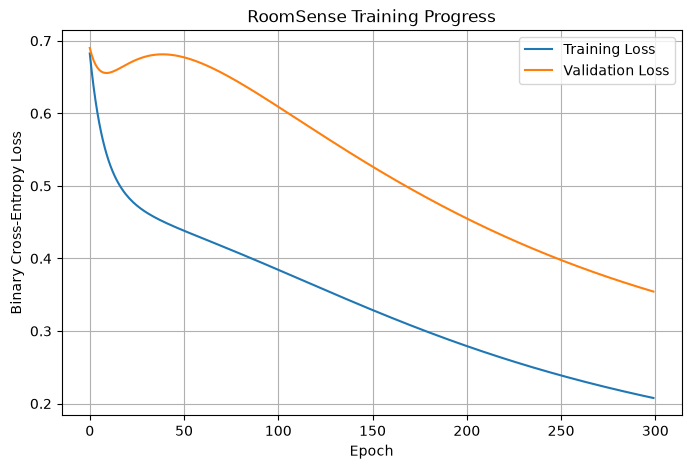

In [55]:
# --- VISUALISE TRAINING PROGRESS ---

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("RoomSense Training Progress")

plt.legend()
plt.grid(True)
plt.show()

### Comparison

In [60]:
# --- WEIGHTED-SUM BASELINE ---

def train_baseline(X, y, learning_rate=0.1, epochs=300):

    # A weighted-sum model has one weight per feature
    weights = np.zeros((X.shape[1], 1))
    bias = 0.0

    y = y.reshape(-1, 1)
    losses = []

    for epoch in range(epochs):

        # Step 1: Calculate weighted sum
        z = X @ weights + bias

        # Step 2: Convert to prediction scores
        predictions = sigmoid(z)

        # Step 3: Calculate the error
        error = predictions - y

        # Step 4: Calculate gradients
        m = len(X)
        dW = X.T @ error / m
        db = np.mean(error)

        # Step 5: Update weights and bias
        weights -= learning_rate * dW
        bias -= learning_rate * db

        # Step 6: Record updated training loss
        updated_predictions = sigmoid(X @ weights + bias)

        loss = binary_cross_entropy(y, updated_predictions)
        losses.append(loss)

    return weights, bias, losses


# Train the baseline on the same training data
baseline_W, baseline_b, baseline_losses = train_baseline(
    X_train_norm,
    y_train,
    learning_rate=0.1,
    epochs=300
)

print("Baseline training completed!")
print("Initial loss:", round(baseline_losses[0], 4))
print("Final loss:", round(baseline_losses[-1], 4))

Baseline training completed!
Initial loss: 0.658
Final loss: 0.0962


### Evaluation

In [61]:
# --- MODEL COMPARISON ---

def evaluate_model(y_true, y_pred):

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    # Confusion matrix counts
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / len(y_true)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    # F1 score for occupied and empty classes
    f1_occupied = (
        2 * TP / (2 * TP + FP + FN)
        if 2 * TP + FP + FN > 0 else 0
    )

    f1_empty = (
        2 * TN / (2 * TN + FP + FN)
        if 2 * TN + FP + FN > 0 else 0
    )

    macro_f1 = (f1_occupied + f1_empty) / 2

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Occupied Recall": recall,
        "Macro-F1": macro_f1,
        "False Negatives": int(FN)
    }


# Baseline predictions
baseline_scores = sigmoid(
    X_val_norm @ baseline_W + baseline_b
)

baseline_predictions = (
    baseline_scores >= 0.5
).astype(int)


# Neural network predictions
hidden = sigmoid(X_val_norm @ W1 + b1)

nn_scores = sigmoid(hidden @ W2 + b2)

nn_predictions = (
    nn_scores >= 0.5
).astype(int)


# Evaluate both models
baseline_results = evaluate_model(
    y_val, baseline_predictions
)

nn_results = evaluate_model(
    y_val, nn_predictions
)


# Display comparison
print("VALIDATION RESULTS")
print("-" * 55)

print(f"{'Metric':20} {'Baseline':>12} {'Neural Net':>12}")

for metric in baseline_results:
    b = baseline_results[metric]
    n = nn_results[metric]

    if metric == "False Negatives":
        print(f"{metric:20} {b:12d} {n:12d}")
    else:
        print(f"{metric:20} {b:12.4f} {n:12.4f}")

VALIDATION RESULTS
-------------------------------------------------------
Metric                   Baseline   Neural Net
Accuracy                   0.8950       0.8711
Precision                  0.8044       0.9749
Occupied Recall            0.9371       0.6599
Macro-F1                   0.8898       0.8473
False Negatives                37          200


### Weighted-Sum Baseline Comparison

I implemented a weighted-sum classifier as a simpler alternative to my neural network. It uses the same four sensor inputs but does not have a hidden layer.

The baseline calculates a weighted sum, applies sigmoid and uses a threshold of 0.5 to classify room occupancy.

I trained both models using the same training split and evaluated them using the same validation split.

I compared accuracy, precision, occupied-room recall, macro-F1 and false negatives. This helps me determine whether the additional complexity of the neural network provides a meaningful improvement.

### Experiment 1

In [62]:
# --- EXPERIMENT 1: LEARNING RATE COMPARISON ---

learning_rates = [0.01, 0.1, 0.5]

# Store the results of each experiment
lr_results = {}

for lr in learning_rates:

    # Train with the selected learning rate
    W1_lr, b1_lr, W2_lr, b2_lr, train_hist, val_hist = train_roomsense(
        X_train_norm,
        y_train,
        X_val_norm,
        y_val,
        learning_rate=lr,
        epochs=300,
        seed=42
    )

    # Make predictions on validation data
    hidden = sigmoid(X_val_norm @ W1_lr + b1_lr)
    scores = sigmoid(hidden @ W2_lr + b2_lr)

    predictions_lr = (scores >= 0.5).astype(int)

    # Calculate evaluation metrics
    metrics = evaluate_model(y_val, predictions_lr)

    # Save results
    lr_results[lr] = {
        "weights": (W1_lr, b1_lr, W2_lr, b2_lr),
        "train_losses": train_hist,
        "val_losses": val_hist,
        "metrics": metrics
    }

    print(f"\nLearning rate: {lr}")
    print(f"Training loss: {train_hist[-1]:.4f}")
    print(f"Validation loss: {val_hist[-1]:.4f}")
    print(f"Accuracy: {metrics['Accuracy']:.4f}")
    print(f"Occupied recall: {metrics['Occupied Recall']:.4f}")
    print(f"Macro-F1: {metrics['Macro-F1']:.4f}")

print("\nExperiment 1 completed!")


Learning rate: 0.01
Training loss: 0.4659
Validation loss: 0.6763
Accuracy: 0.6390
Occupied recall: 0.0000
Macro-F1: 0.3899

Learning rate: 0.1
Training loss: 0.2077
Validation loss: 0.3544
Accuracy: 0.8711
Occupied recall: 0.6599
Macro-F1: 0.8473

Learning rate: 0.5
Training loss: 0.0661
Validation loss: 0.2222
Accuracy: 0.9036
Occupied recall: 0.9983
Macro-F1: 0.9003

Experiment 1 completed!


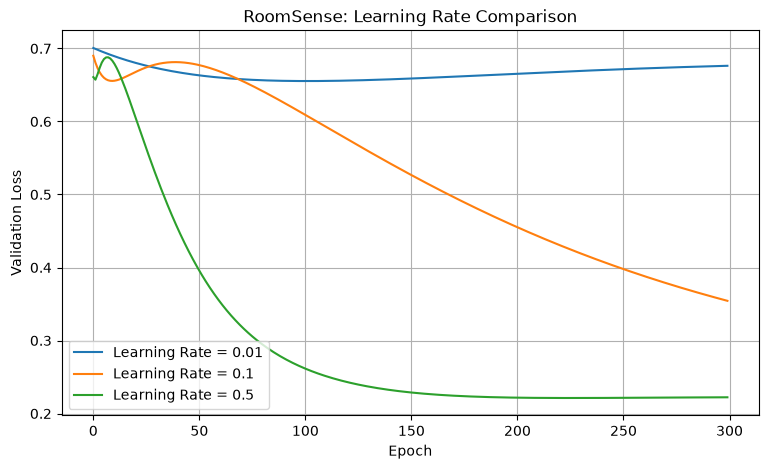

In [63]:
# --- GRAPH 1: VALIDATION LOSS VS LEARNING RATE ---

from pathlib import Path

figures_path = Path("figures")
figures_path.mkdir(exist_ok=True)

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        lr_results[lr]["val_losses"],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("RoomSense: Learning Rate Comparison")

plt.legend()
plt.grid(True)

plt.savefig(
    figures_path / "learning_rate_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [64]:
# --- COMPARE LEARNING RATE RESULTS ---

print(f"{'Learning Rate':<16} {'Macro-F1':<12} {'Occupied Recall':<18}")
print("-" * 50)

for lr in learning_rates:
    metrics = lr_results[lr]["metrics"]

    print(
        f"{lr:<16}"
        f"{metrics['Macro-F1']:<12.4f}"
        f"{metrics['Occupied Recall']:<18.4f}"
    )

# Select by validation Macro-F1, then occupied recall
best_lr = max(
    learning_rates,
    key=lambda lr: (
        lr_results[lr]["metrics"]["Macro-F1"],
        lr_results[lr]["metrics"]["Occupied Recall"]
    )
)

print("\nBest validation learning rate:", best_lr)

Learning Rate    Macro-F1     Occupied Recall   
--------------------------------------------------
0.01            0.3899      0.0000            
0.1             0.8473      0.6599            
0.5             0.9003      0.9983            

Best validation learning rate: 0.5


### Experiment 1: Learning Rate Comparison

**Aim:** To investigate how different learning rates affect the training and performance of RoomSense.

**Method:** I trained the same neural network using learning rates of 0.01, 0.1 and 0.5. Each model used the same training and validation data, random seed, architecture and 300 epochs. The learning rate was the main variable changed.

**Evaluation:** I recorded training loss, validation loss, accuracy, occupied recall and macro-F1. I also plotted validation loss across epochs to compare the learning process.

**Results:** The learning rate had a clear effect on the performance of RoomSense. A learning rate of 0.01 performed poorly, achieving a macro-F1 of 0.3899 and an occupied recall of 0.0000. This means it failed to correctly identify any occupied rooms in the validation data.

Increasing the learning rate to 0.1 improved the macro-F1 to 0.8473 and occupied recall to 0.6599.

The best results came from a learning rate of 0.5, which achieved a macro-F1 of 0.9003 and occupied recall of 0.9983. This was the best-performing learning rate out of the three tested.

**Conclusion:** This experiment showed me how important the learning rate is when training a neural network. A smaller learning rate did not allow RoomSense to learn effectively within the 300 epochs used, while 0.5 performed much better.

I selected 0.5 for the next experiment because it achieved the highest validation macro-F1 and occupied recall. This connects to P9 Gradient Descent, where I learned that the learning rate affects how quickly the algorithm moves towards a lower loss.

However, a larger learning rate is not always better, and these results only show that 0.5 worked best among the three values I tested.

### Experiment 2

In [65]:
# --- EXPERIMENT 2: SENSOR RELIABILITY ---

# Test different light sensor failure rates
failure_rates = [0, 25, 50, 100]

# Find which column contains light readings
light_index = features.index("Light")

# Use the best learning rate from Experiment 1
W1_best, b1_best, W2_best, b2_best = lr_results[best_lr]["weights"]

# Keep the same random selection of failed rows
rng = np.random.default_rng(2026)
sensor_order = rng.permutation(len(X_val))

sensor_results = {}

for failure_rate in failure_rates:

    # Make a copy so original data stays unchanged
    X_corrupted = X_val.copy()

    # Determine how many sensor readings to change
    n_failed = round(len(X_corrupted) * failure_rate / 100)

    # Choose the affected rows
    failed_rows = sensor_order[:n_failed]

    # Simulate a faulty light sensor reporting zero
    X_corrupted[failed_rows, light_index] = 0.0

    # Standardise using ORIGINAL training statistics
    X_corrupted_norm = (
        X_corrupted - train_mean
    ) / train_std

    # Neural network predictions
    H = sigmoid(X_corrupted_norm @ W1_best + b1_best)
    nn_scores = sigmoid(H @ W2_best + b2_best)
    nn_preds = (nn_scores >= 0.5).astype(int)

    # Weighted-sum baseline predictions
    baseline_scores = sigmoid(
        X_corrupted_norm @ baseline_W + baseline_b
    )
    baseline_preds = (baseline_scores >= 0.5).astype(int)

    # Evaluate both models
    nn_metrics = evaluate_model(y_val, nn_preds)
    baseline_metrics = evaluate_model(y_val, baseline_preds)

    # Save the results
    sensor_results[failure_rate] = {
        "Neural Network": nn_metrics,
        "Baseline": baseline_metrics
    }

    print(f"\nLight sensor failure rate: {failure_rate}%")
    print(f"Affected observations: {n_failed}")

    print(
        f"NN Occupied Recall: "
        f"{nn_metrics['Occupied Recall']:.4f}"
    )

    print(
        f"NN Macro-F1: "
        f"{nn_metrics['Macro-F1']:.4f}"
    )

    print(
        f"NN False Negatives: "
        f"{nn_metrics['False Negatives']}"
    )

    print(
        f"Baseline Occupied Recall: "
        f"{baseline_metrics['Occupied Recall']:.4f}"
    )

    print(
        f"Baseline Macro-F1: "
        f"{baseline_metrics['Macro-F1']:.4f}"
    )

print("\nSensor reliability experiment completed!")


Light sensor failure rate: 0%
Affected observations: 0
NN Occupied Recall: 0.9983
NN Macro-F1: 0.9003
NN False Negatives: 1
Baseline Occupied Recall: 0.9371
Baseline Macro-F1: 0.8898

Light sensor failure rate: 25%
Affected observations: 407
NN Occupied Recall: 0.9439
NN Macro-F1: 0.8790
NN False Negatives: 33
Baseline Occupied Recall: 0.8980
Baseline Macro-F1: 0.8741

Light sensor failure rate: 50%
Affected observations: 814
NN Occupied Recall: 0.8946
NN Macro-F1: 0.8606
NN False Negatives: 62
Baseline Occupied Recall: 0.8622
Baseline Macro-F1: 0.8595

Light sensor failure rate: 100%
Affected observations: 1629
NN Occupied Recall: 0.7976
NN Macro-F1: 0.8224
NN False Negatives: 119
Baseline Occupied Recall: 0.7874
Baseline Macro-F1: 0.8282

Sensor reliability experiment completed!


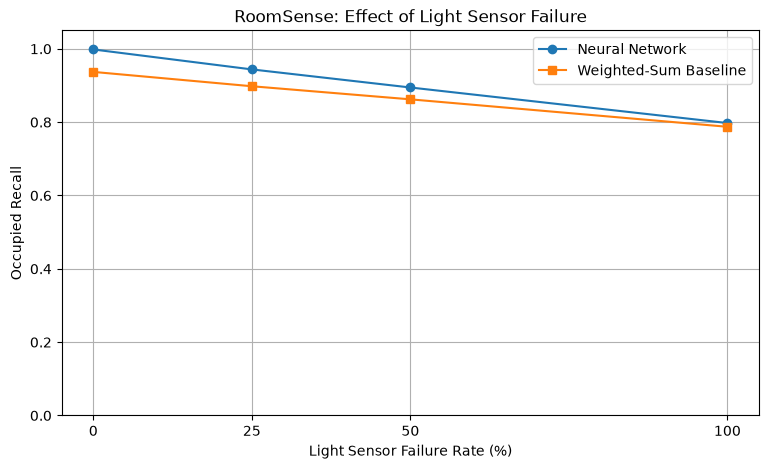

In [66]:
# --- GRAPH 2: SENSOR RELIABILITY ---

failure_rates = [0, 25, 50, 100]

nn_recalls = [
    sensor_results[rate]["Neural Network"]["Occupied Recall"]
    for rate in failure_rates
]

baseline_recalls = [
    sensor_results[rate]["Baseline"]["Occupied Recall"]
    for rate in failure_rates
]

plt.figure(figsize=(9, 5))

plt.plot(
    failure_rates,
    nn_recalls,
    marker="o",
    label="Neural Network"
)

plt.plot(
    failure_rates,
    baseline_recalls,
    marker="s",
    label="Weighted-Sum Baseline"
)

plt.xlabel("Light Sensor Failure Rate (%)")
plt.ylabel("Occupied Recall")
plt.title("RoomSense: Effect of Light Sensor Failure")

plt.xticks(failure_rates)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(True)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "sensor_reliability.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Experiment 2: Light Sensor Reliability

**Aim:** To investigate how unreliable light sensor readings affect RoomSense's predictions.

**Method:** I simulated a faulty light sensor by replacing 0%, 25%, 50% and 100% of the validation light readings with zero. I kept the trained models and actual occupancy labels unchanged.

I used the original training mean and standard deviation to standardise the modified data.

**Evaluation:** I compared occupied recall, macro-F1 and false negatives for the neural network and weighted-sum baseline.

**Results:** The neural network performed well when the light sensor was working normally, achieving an occupied recall of 0.9983 and macro-F1 of 0.9003. It only missed one occupied room.

As the light sensor failure rate increased, the performance of both models decreased. At 50% failure, the neural network's occupied recall dropped to 0.8946, with 62 false negatives.

At 100% failure, the neural network's occupied recall dropped to 0.7976, with 119 false negatives. The weighted-sum baseline achieved a slightly lower recall of 0.7874, but a slightly higher macro-F1 of 0.8282 compared to the neural network's 0.8224.

**Conclusion:** This experiment showed me that RoomSense depends heavily on reliable sensor data. The neural network generally identified more occupied rooms than the baseline, even when some light readings were incorrect.

However, when all light readings were replaced with zero, both models performed worse. The baseline also achieved a slightly better macro-F1 under complete light sensor failure.

This showed me that using a more complex neural network does not guarantee better performance in every situation. Reliable inputs are still important.

**Limitation:** I only tested one type of sensor failure by replacing light readings with zero. Real sensor failures may behave differently, so this experiment does not fully represent real-world reliability.

In [67]:
# --- EXPERIMENT 2: EXACT RESULTS TABLE ---

print(
    f"{'Failure':<10} {'Model':<20} "
    f"{'Recall':<12} {'Macro-F1':<12} {'False Negatives'}"
)
print("-" * 75)

for rate in failure_rates:
    for model in ["Neural Network", "Baseline"]:
        result = sensor_results[rate][model]

        print(
            f"{rate:<10} {model:<20} "
            f"{result['Occupied Recall']:<12.4f} "
            f"{result['Macro-F1']:<12.4f} "
            f"{result['False Negatives']}"
        )

Failure    Model                Recall       Macro-F1     False Negatives
---------------------------------------------------------------------------
0          Neural Network       0.9983       0.9003       1
0          Baseline             0.9371       0.8898       37
25         Neural Network       0.9439       0.8790       33
25         Baseline             0.8980       0.8741       60
50         Neural Network       0.8946       0.8606       62
50         Baseline             0.8622       0.8595       81
100        Neural Network       0.7976       0.8224       119
100        Baseline             0.7874       0.8282       125


## Final Evaluation

In [68]:
# --- FINAL EVALUATION ---

# Use the learning rate selected from validation results
print("Selected learning rate:", best_lr)

# Retrieve the selected neural network weights
W1_final, b1_final, W2_final, b2_final = lr_results[best_lr]["weights"]

# Keep the official test datasets separate
test_sets = {
    "Test Set 1": (X_test1, y_test1),
    "Test Set 2": (X_test2, y_test2)
}

final_results = {}

for test_name, (X_test, y_test) in test_sets.items():

    # Standardise using training statistics ONLY
    X_test_norm = (X_test - train_mean) / train_std

    # Neural network predictions
    H = sigmoid(X_test_norm @ W1_final + b1_final)
    nn_scores = sigmoid(H @ W2_final + b2_final)
    nn_preds = (nn_scores >= 0.5).astype(int)

    # Baseline predictions
    baseline_scores = sigmoid(
        X_test_norm @ baseline_W + baseline_b
    )
    baseline_preds = (baseline_scores >= 0.5).astype(int)

    # Evaluate both models
    nn_metrics = evaluate_model(y_test, nn_preds)
    baseline_metrics = evaluate_model(y_test, baseline_preds)

    # Save results
    final_results[test_name] = {
        "Neural Network": nn_metrics,
        "Baseline": baseline_metrics,
        "y_true": y_test,
        "nn_predictions": nn_preds.flatten(),
        "baseline_predictions": baseline_preds.flatten()
    }

    print(f"\n--- {test_name} ---")
    print("Number of observations:", len(y_test))

    print("\nNeural Network:")
    for metric, value in nn_metrics.items():
        print(f"{metric}: {value:.4f}" if isinstance(value, float)
              else f"{metric}: {value}")

    print("\nWeighted-Sum Baseline:")
    for metric, value in baseline_metrics.items():
        print(f"{metric}: {value:.4f}" if isinstance(value, float)
              else f"{metric}: {value}")

print("\nFinal evaluation completed!")


Selected learning rate: 0.5

--- Test Set 1 ---
Number of observations: 2665

Neural Network:
Accuracy: 0.9568
Precision: 0.8979
Occupied Recall: 0.9949
Macro-F1: 0.9544
False Negatives: 5

Weighted-Sum Baseline:
Accuracy: 0.9535
Precision: 0.9077
Occupied Recall: 0.9712
Macro-F1: 0.9505
False Negatives: 28

--- Test Set 2 ---
Number of observations: 9752

Neural Network:
Accuracy: 0.8799
Precision: 0.6368
Occupied Recall: 0.9971
Macro-F1: 0.8475
False Negatives: 6

Weighted-Sum Baseline:
Accuracy: 0.8870
Precision: 0.6510
Occupied Recall: 0.9961
Macro-F1: 0.8552
False Negatives: 8

Final evaluation completed!


In [69]:
# --- FINAL MODEL COMPARISON TABLE ---

print(
    f"{'Dataset':<14} {'Model':<18} "
    f"{'Accuracy':<12} {'Macro-F1':<12} "
    f"{'Recall':<12} {'False Negatives'}"
)

print("-" * 85)

for test_name in test_sets:
    for model in ["Neural Network", "Baseline"]:

        result = final_results[test_name][model]

        print(
            f"{test_name:<14} "
            f"{model:<18} "
            f"{result['Accuracy']:<12.4f} "
            f"{result['Macro-F1']:<12.4f} "
            f"{result['Occupied Recall']:<12.4f} "
            f"{result['False Negatives']}"
        )

Dataset        Model              Accuracy     Macro-F1     Recall       False Negatives
-------------------------------------------------------------------------------------
Test Set 1     Neural Network     0.9568       0.9544       0.9949       5
Test Set 1     Baseline           0.9535       0.9505       0.9712       28
Test Set 2     Neural Network     0.8799       0.8475       0.9971       6
Test Set 2     Baseline           0.8870       0.8552       0.9961       8


In [70]:
# --- CHECK H1 SUCCESS CRITERIA ---

for test_name in test_sets:

    nn = final_results[test_name]["Neural Network"]
    baseline = final_results[test_name]["Baseline"]

    f1_target = nn["Macro-F1"] >= 0.80
    recall_target = nn["Occupied Recall"] >= 0.90

    f1_improvement = (
        nn["Macro-F1"] - baseline["Macro-F1"]
    )

    improvement_target = (
        f1_improvement >= 0.02
        and nn["Occupied Recall"] >= baseline["Occupied Recall"]
    )

    print(f"\n{test_name}")
    print("Macro-F1 >= 80%:", f1_target)
    print("Occupied recall >= 90%:", recall_target)
    print("NN improvement target:", improvement_target)
    print("Macro-F1 improvement:", round(f1_improvement, 4))


Test Set 1
Macro-F1 >= 80%: True
Occupied recall >= 90%: True
NN improvement target: False
Macro-F1 improvement: 0.0039

Test Set 2
Macro-F1 >= 80%: True
Occupied recall >= 90%: True
NN improvement target: False
Macro-F1 improvement: -0.0077


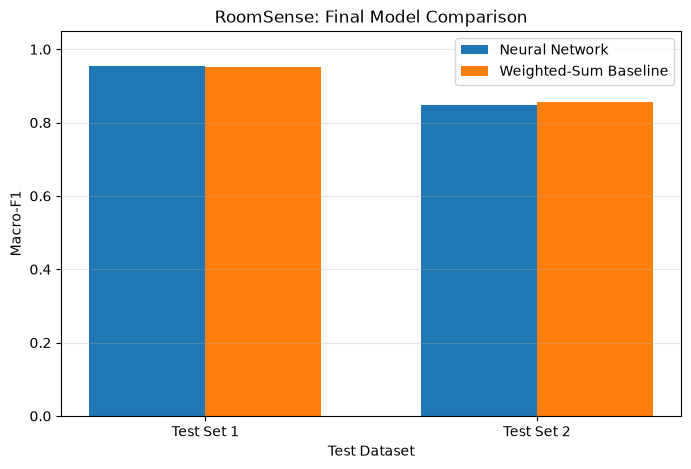

In [71]:
# --- FINAL GRAPH: TEST PERFORMANCE COMPARISON ---

test_names = list(test_sets.keys())

nn_f1 = [
    final_results[name]["Neural Network"]["Macro-F1"]
    for name in test_names
]

baseline_f1 = [
    final_results[name]["Baseline"]["Macro-F1"]
    for name in test_names
]

x = np.arange(len(test_names))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    nn_f1,
    width,
    label="Neural Network"
)

plt.bar(
    x + width / 2,
    baseline_f1,
    width,
    label="Weighted-Sum Baseline"
)

plt.xlabel("Test Dataset")
plt.ylabel("Macro-F1")
plt.title("RoomSense: Final Model Comparison")

plt.xticks(x, test_names)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "final_model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Final Model Evaluation

### Aim
To evaluate how well RoomSense performs on unseen data and compare the neural network against the simpler weighted-sum baseline.

### Method
I evaluated both models using the two official UCI test datasets, which were kept separate during training and validation.

I selected a learning rate of 0.5 for the neural network based on the validation results from Experiment 1. I used the original training mean and standard deviation to standardise the test data.

Both models were evaluated using the same test examples and a classification threshold of 0.5.

### Evaluation Metrics
I used accuracy, precision, occupied recall, macro-F1 and false negatives to evaluate both models.

I focused mainly on macro-F1 and occupied recall because I wanted the model to perform well across both classes while reducing the number of occupied rooms incorrectly predicted as empty.

### Results
The neural network performed well on both unseen test datasets.

On Test Set 1, both models achieved a macro-F1 of approximately 0.95. The neural network performed slightly better, with a macro-F1 improvement of 0.0039 (0.39 percentage points) compared to the baseline.

On Test Set 2, both models achieved a macro-F1 of approximately 0.85. However, the weighted-sum baseline performed slightly better, with the neural network scoring 0.0077 lower in macro-F1 (0.77 percentage points).

The graph shows that the performance of both models was lower on Test Set 2 than Test Set 1. This suggests that some observations may be more difficult to classify.

Overall, both models performed similarly, and the neural network did not show a large improvement over the simpler baseline.

### Comparison with H1 Goals

In H1, I set three main success targets:

| H1 Success Criteria | Test Set 1 | Test Set 2 |
|---|---|---|
| Macro-F1 of at least 80% | Achieved | Achieved |
| Occupied recall of at least 90% | Achieved | Achieved |
| At least 2 percentage points higher macro-F1 than baseline, without reducing occupied recall | Not achieved | Not achieved |

The neural network achieved the first two targets on both test datasets, meaning it performed well at identifying occupied rooms while maintaining good performance across both classes.

However, it did not achieve the improvement target. On Test Set 1, the improvement was only 0.39 percentage points, which was below my 2-percentage-point target.

On Test Set 2, the baseline actually achieved a slightly higher macro-F1 than the neural network.

Therefore, RoomSense achieved two out of three H1 success criteria on both test datasets.

### Conclusion
The final evaluation showed that RoomSense can predict room occupancy effectively using temperature, humidity, light and CO2 readings.

I was happy that the neural network achieved the macro-F1 and occupied recall targets from my original H1 plan.

However, I also learned that a more complicated model does not always perform better. The weighted-sum baseline achieved very similar results and even performed slightly better on Test Set 2.

This means the additional complexity of the neural network was not clearly justified by the performance improvement in this experiment.

Overall, the project helped me understand how neural networks learn and why comparing models using unseen data is important.

### Limitations and Future Improvements
One limitation is that I only used four sensor features and a small neural-network architecture. Different settings or additional features might improve performance.

My second experiment also showed that unreliable light sensor readings can reduce occupied recall. This suggests that RoomSense would need further reliability testing before being used in a real building.

In the future, I could investigate different hidden-layer sizes, classification thresholds and ways of handling missing or faulty sensor readings.

I would also test the model using data collected from different buildings to understand whether it performs well in other environments.

In [ ]:
# --- REPORT: EXACT FINAL RESULTS ---

print("| Dataset | Model | Accuracy | Precision | Occupied Recall | Macro-F1 | False Negatives |")
print("|---|---|---:|---:|---:|---:|---:|")

for test_name in ["Test Set 1", "Test Set 2"]:
    for model in ["Neural Network", "Baseline"]:
        r = final_results[test_name][model]

        print(
            f"| {test_name} | {model} | "
            f"{r['Accuracy']:.4f} | "
            f"{r['Precision']:.4f} | "
            f"{r['Occupied Recall']:.4f} | "
            f"{r['Macro-F1']:.4f} | "
            f"{r['False Negatives']} |"
        )

| Dataset | Model | Accuracy | Precision | Occupied Recall | Macro-F1 | False Negatives |
|---|---|---:|---:|---:|---:|---:|
| Test Set 1 | Neural Network | 0.9568 | 0.8979 | 0.9949 | 0.9544 | 5 |
| Test Set 1 | Baseline | 0.9535 | 0.9077 | 0.9712 | 0.9505 | 28 |
| Test Set 2 | Neural Network | 0.8799 | 0.6368 | 0.9971 | 0.8475 | 6 |
| Test Set 2 | Baseline | 0.8870 | 0.6510 | 0.9961 | 0.8552 | 8 |


: 

### Visualisation 1

In [58]:
# --- VISUALISATION 1 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

### Visualisation 2

In [59]:
# --- VISUALISATION 2 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

*For the FIT1061 project, RoomSense, a tiny neural network to predict occupancy of an office room using the sensor data, was created. I used the four features of temperature, humidity, light and CO2.

My primary issue was to be able to determine the occupancy of a room without someone having to look and see if a room is occupied. This can help in the smart use of energy in buildings. For instance, if a building-management system is aware of when a room is empty, it could adjust lighting or air conditioning settings accordingly. But my project doesn't actually directly control building equipment, nor measure energy savings, just predict occupancy.

I selected Artificial Intelligence because sometimes the occupancy can rely on several readings from the sensors. A simple rule might not recognise all the different combinations of readings. Examples from a set of data can be used to learn relationships between these features by a neural network.

I took the UCI Occupancy Detection dataset with real measurements from sensors and their correct occupancy label.

The primary objective was to develop a functioning NN from scratch and examine if it outperformed the simpler NN of weighted sum classification. I also wanted to know how training settings and bad sensor readings impacted performance.*

### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

*I used Python, NumPy and Jupyter Notebook to implement RoomSense. The reason I didn't use a framework like Tensorflow or PyTorch, is that I wanted to get an understanding of how the neural network works internally.

There are 4 inputs, 1 hidden layer (6 neurons), and 1 output neuron in the neural network. The sigmoid activation function was used in both layers because it will give values in the range 0 to 1. The final output is the model's prediction, which I thresholded at 0.5 to get the model's occupancy score.

Prior to training, I loaded the data set, and chose the four features of the sensors. I split the original data into 80% training/20% validation, but maintained the time ordering of the data.

I have also shrunk the data as the numbers from the sensors are on different scales. For instance CO2 values may be quite high compared to the temperature values. To prevent data leakage, I used only training data for calculating the mean and standard deviation.

I performed forward propagation and used the weights and biases to make predictions. Errors in prediction were measured using binary cross-entropy.

Then I used back-propagation to get the gradients and gradient descent to update the weights. The model was run for more than 300 epochs with full-batch training.

To analyse the impact of learning rates on learning process, I tried various learning rates.

I also added a baseline (without any hidden layer) based on weighted sum. I was able to do this using the same training and validation data set to compare the neural network to a simpler approach.

Finally, I tested both models in terms of accuracy, precision, occupied recall, macro-F1 and false-negatives. I paid special attention to occupied recall, where I tried to have as few of the occupied rooms as possible wrongly classified as vacant.*

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

*I ran two large experiments to explore how well and reliably RoomSense works.

Experiment 1: Comparing the learning rates of different subjects.

In experiment 1 I used learning rate values 0.01, 0.1 and 0.5. The architecture, random seed, training data, and number of epochs were kept the same to ensure that the learning rate was the only variable to change.

Learning Rate | Macro-F1 | Occupied Recall |
|---|---|---|
| 0.01 | 0.3899 | 0.0000 |
| 0.1 | 0.8473 | 0.6599 |
| 0.5 | 0.9003 | 0.9983 |

The results indicated that the learning rate was the most important factor in performance. The neural network was not able to correctly identify any rooms when tested on the validation dataset at 0.01.

The performance was improved with learning rate 0.1 but the occupied recall was still 0.6599.

The best macro-F1 achieved was 0.9003 with occupying recall of 0.9983 for the 0.5 setting.

The learning-rate comparison plot displayed the evolution of the validation loss over training. I chose 0.5 for the rest of the experiments because it got the best validation macro-F1 score.

This was linked to P9 Gradient Descent, where I learnt that smaller learning rates update the parameters by a smaller amount. The findings, however, do not imply that it is always good to have high learning rates.*

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

*Despite the success of RoomSense, there are still a few issues.

A drawback is that I only explored one neural-network architecture, namely one that contains six hidden neurons. The performance may be improved for other architectures, but I didn't have enough time to explore many.

The another drawback is that RoomSense relies on the accuracy of the sensor readings. When the light sensor was unreliable in Experiment 2, there was a significant decrease in occupied recall. This demonstrated that the model might be inaccurate when the input is not correct.

A fixed classification threshold value was also used, which was 0.5. There may be another threshold that could help decrease the rate of false negatives, but increase the rate of false positives.

The dataset is a small environment and the results are not intended to demonstrate the performance of RoomSense under different environments or building conditions.

I would love to try out different sizes of the hidden layers, explore other classification thresholds, and also try out other types of sensor failure.

I would also like to investigate whether it would be possible to use even more sensor traits to further enhance the reliability of the model.

Lastly, I would test RoomSense with data from other rooms or buildings to see if it is able to generalise to situations outside the dataset.*

### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

*In a real building, when RoomSense was used, it will impact the work of the employees, building managers and others using the rooms.

The most dangerous issue would be a false negative prediction, or the system predicting a room as empty when it is, in reality, occupied.

If a building-management system used this forecast to lower the temperature of an air conditioning system or reduce lighting in a room, for instance, the people inside could be impacted.

This relates to the work I did on classification errors and fairness in C2. We don't need to limit our failures to accuracy since I measured occupied recall and false negatives too.

I would also want to review if the model works differently in different rooms, different lighting or at different times of the day. This often occurs when a system that is successful in one place is not successful in another.

Another thing that is considered is privacy. Even if the model does not identify who the people are, occupancy information could be used to monitor people's activities.

This relates to the significance of documenting the usage of an AI model (C4). A model card might incorporate information on the purpose of a RoomSense, the evaluation outcomes, and limitations and known risks.

I think that RoomSense shouldn't be used to automatically control important building systems without the human supervision.

In general, this project has given me insight into the fact that creating Artificial Intelligence is not only about accuracy. It is also important to be aware of the implications of wrong predictions and to employ the model appropriately.*

### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

*I utilized ChatGPT for my RoomSense project for concepts, error troubleshooting and validation of my implementation. Partially used AI to assist in the organisation and enhancement of parts of my report.

I took suggestions that would fit into my project, and compared their findings to my results. I also adapted suggestions that were not found in the same way as in my notebook, and did not include example results as findings.

In general, AI assisted with implementing, testing, debugging and documenting.*

---

## Submission Checklist

- [x] Recap of H1 scope (and any pivot) at the top
- [x] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [x] Project report (~1500 words) covering all 6 sections
- [x] Implementation demonstrates HD-level depth beyond earlier task work
- [x] Ethical reflection connects to C2 or C4
- [x] AI use statement shows critical evaluation
- [x] Code is readable, reproducible, documented
- [x] Uploaded to OnTrack and marked **Ready for Feedback**
- [x] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*